# LAB – Clustering (IA não supervisionada): K-Means com o dataset Country Data

**PUC-SP – Ciência da Computação – Inteligência Artificial (IA ML)**

**Alunos:**
- João Avila Harduin - RA00332195
- Kauã Cordeiro Cavalheiro - RA00331660

**Objetivo:** experimentar e explorar um modelo de *clustering* (agrupamento) com Scikit-Learn: o **K-Means** (`KMeans`).

**Dataset:** [Unsupervised Learning on Country Data](https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data) do Kaggle.
São indicadores socioeconômicos e de saúde de 167 países (mortalidade infantil, renda, PIB per capita, expectativa de vida etc.).

**Problema:** aprendizado **não supervisionado**. Não existe uma coluna "resposta". O objetivo é descobrir grupos de países com perfis
parecidos, por exemplo para ajudar uma ONG a decidir quais países mais precisam de ajuda humanitária.

## 1. Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
CORES = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#DD8452", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD"]

## 2. Carregando os dados

In [2]:
CAMINHO = "Country-data.csv"

try:
    df = pd.read_csv(CAMINHO)
except FileNotFoundError:
    import kagglehub
    pasta = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
    df = pd.read_csv(f"{pasta}/Country-data.csv")

print("Dimensões:", df.shape)
df.head()

100%|██████████| 5.21k/5.21k [00:00<00:00, 5.00MB/s]

Extracting files...
Dimensões: (167, 10)


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


**Dicionário das colunas:**

| Coluna | Significado |
|---|---|
| `country` | Nome do país |
| `child_mort` | Mortes de crianças menores de 5 anos a cada 1000 nascidos vivos |
| `exports` | Exportações (% do PIB) |
| `health` | Gasto com saúde (% do PIB) |
| `imports` | Importações (% do PIB) |
| `income` | Renda líquida por pessoa |
| `inflation` | Inflação anual (%) |
| `life_expec` | Expectativa de vida (anos) |
| `total_fer` | Número médio de filhos por mulher |
| `gdpp` | PIB per capita |

## 3. Análise exploratória

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


In [4]:
print("Valores ausentes por coluna:")
print(df.isna().sum())
print("\nPaíses duplicados:", df["country"].duplicated().sum())

Valores ausentes por coluna:
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Países duplicados: 0


In [5]:
df.describe().round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00
mean,38.27,41.11,6.82,46.89,17144.69,7.78,70.56,2.95,12964.16
std,40.33,27.41,2.75,24.21,19278.07,10.57,8.89,1.51,18328.70
min,2.60,0.11,1.81,0.07,609.00,-4.21,32.10,1.15,231.00
25%,8.25,23.80,4.92,30.20,3355.00,1.81,65.30,1.80,1330.00
50%,19.30,35.00,6.32,43.30,9960.00,5.39,73.10,2.41,4660.00
75%,62.10,51.35,8.60,58.75,22800.00,10.75,76.80,3.88,14050.00
max,208.00,200.00,17.90,174.00,125000.00,104.00,82.80,7.49,105000.00


Observações:
- O dataset não tem valores ausentes, então não precisamos de `SimpleImputer`.
- As variáveis estão em **escalas muito diferentes**: `income` e `gdpp` chegam a dezenas de milhares, enquanto `total_fer` fica entre 1 e 8.

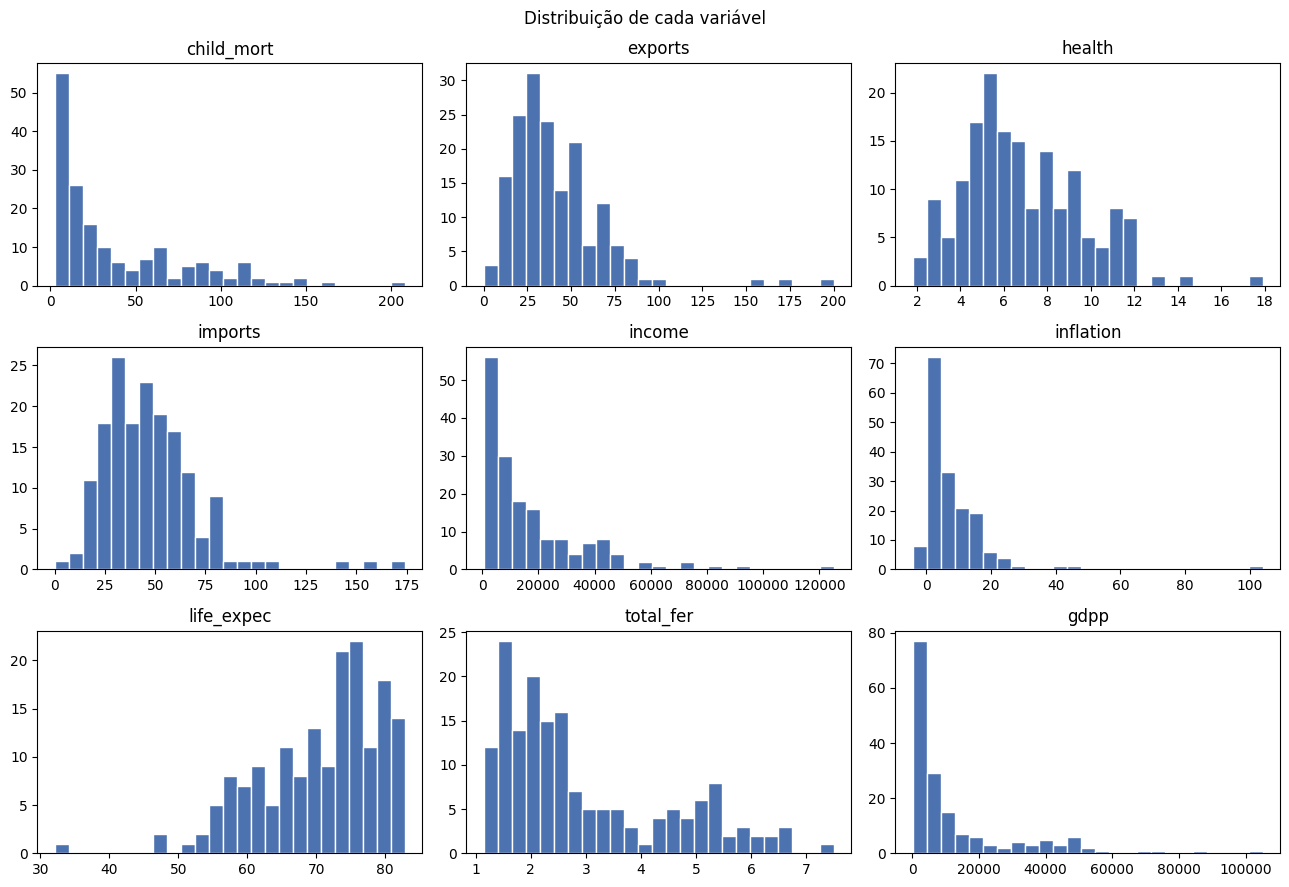

Assimetria (skewness) de cada variável:
inflation     5.15
exports       2.45
income        2.23
gdpp          2.22
imports       1.91
child_mort    1.45
total_fer     0.97
health        0.71
life_expec   -0.97
dtype: float64


In [6]:
features = ["child_mort", "exports", "health", "imports", "income",
            "inflation", "life_expec", "total_fer", "gdpp"]

fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col], bins=25, color="#4C72B0", edgecolor="white")
    ax.set_title(col)
plt.suptitle("Distribuição de cada variável")
plt.tight_layout()
plt.show()

print("Assimetria (skewness) de cada variável:")
print(df[features].skew().round(2).sort_values(ascending=False))

Várias variáveis (`income`, `gdpp`, `child_mort`, `exports`, `imports`, `inflation`) têm **cauda longa à direita**: poucos países
muito ricos ou com valores extremos. Isso atrapalha modelos baseados em distância, porque esses poucos países "puxam" os centros dos grupos.

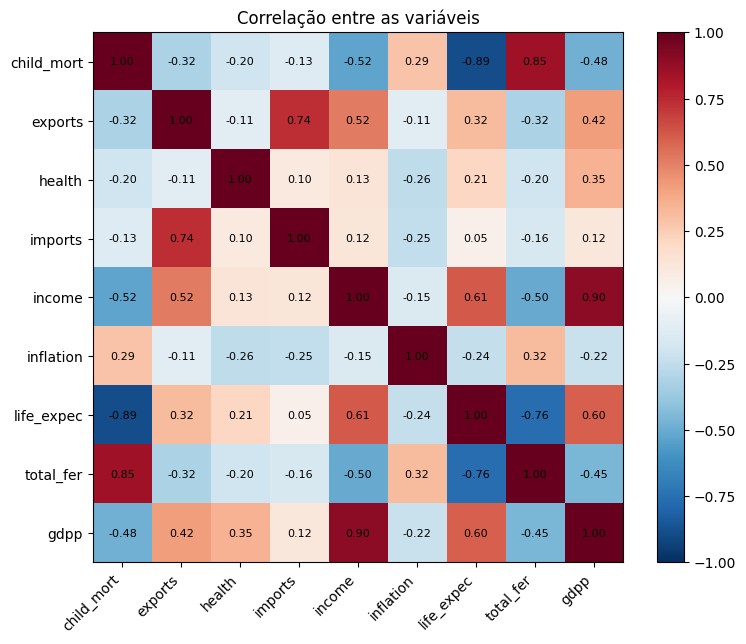

In [7]:
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=45, ha="right")
ax.set_yticks(range(len(features)), features)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlação entre as variáveis")
plt.tight_layout()
plt.show()

A matriz mostra grupos de variáveis que andam juntas:
- `income` e `gdpp` são fortemente correlacionadas (países ricos têm renda alta).
- `child_mort` e `total_fer` sobem juntas e caem quando `life_expec` sobe.

Ou seja, existe uma dimensão principal de **"nível de desenvolvimento"** nos dados, o que sugere que os países vão formar grupos.

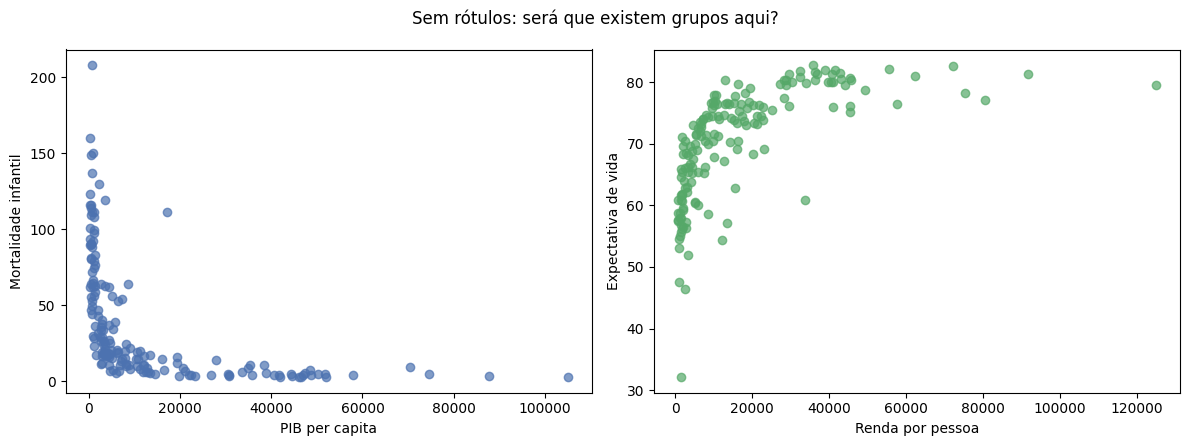

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(df["gdpp"], df["child_mort"], alpha=0.7, c="#4C72B0")
axes[0].set_xlabel("PIB per capita"); axes[0].set_ylabel("Mortalidade infantil")
axes[1].scatter(df["income"], df["life_expec"], alpha=0.7, c="#55A868")
axes[1].set_xlabel("Renda por pessoa"); axes[1].set_ylabel("Expectativa de vida")
plt.suptitle("Sem rótulos: será que existem grupos aqui?")
plt.tight_layout()
plt.show()

## 4. Pré-processamento

- **`country`** é só um identificador, então fica de fora do modelo (mas guardamos para interpretar os grupos depois).
- **Transformação logarítmica (`log1p`)** nas variáveis com cauda longa e sem valores negativos, para reduzir o peso dos extremos.
  A `inflation` tem valores negativos, então não aplicamos log nela.
- **Padronização (`StandardScaler`)**: obrigatória aqui. No LAB anterior, as árvores de decisão não precisavam de escala, mas
  o K-Means usa **distância euclidiana**. Sem padronizar, `gdpp` (valores na casa dos milhares)
  dominaria totalmente o cálculo e as outras variáveis seriam ignoradas.

In [9]:
features_log = ["child_mort", "exports", "imports", "income", "gdpp"]

X = df[features].copy()
X[features_log] = np.log1p(X[features_log])

escalador = StandardScaler()
X_scaled = escalador.fit_transform(X)

print("Assimetria depois do log:")
print(X[features_log].skew().round(2))
print("\nMédia depois da padronização:", X_scaled.mean(axis=0).round(2))
print("Desvio padrão depois da padronização:", X_scaled.std(axis=0).round(2))

Assimetria depois do log:
child_mort    0.07
exports      -1.09
imports      -1.82
income       -0.24
gdpp          0.01
dtype: float64

Média depois da padronização: [-0. -0.  0.  0.  0. -0.  0.  0. -0.]
Desvio padrão depois da padronização: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


### PCA para visualização

Temos 9 dimensões e não dá para desenhar isso. Usamos **PCA** só para projetar os dados em 2 dimensões e conseguir **ver** os grupos.
O clustering é feito com as 9 variáveis padronizadas, e não com a projeção.

Variância explicada por componente: [0.528 0.169]
Total explicado pelas 2 componentes: 69.7%


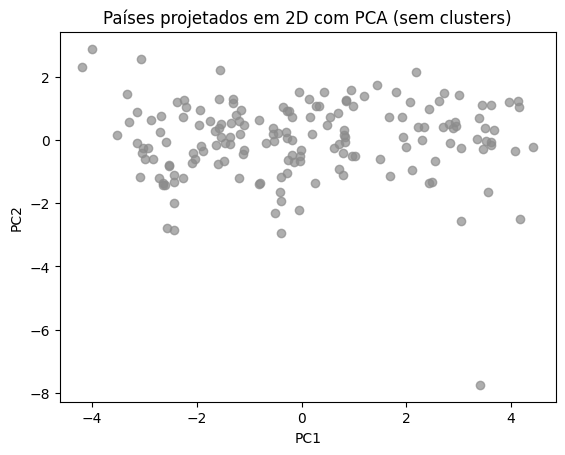

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print("Variância explicada por componente:", pca.explained_variance_ratio_.round(3))
print(f"Total explicado pelas 2 componentes: {pca.explained_variance_ratio_.sum():.1%}")

plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7, c="#8C8C8C")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Países projetados em 2D com PCA (sem clusters)")
plt.show()

### Funções auxiliares

Para não repetir código, criamos funções para: desenhar os grupos no plano do PCA, calcular as métricas de qualidade e
dar nomes aos grupos de acordo com o PIB per capita médio.

In [11]:
def plot_clusters(labels, titulo, nomes=None):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    for i, grupo in enumerate(np.unique(labels)):
        mascara = labels == grupo
        rotulo = nomes[grupo] if nomes else f"Grupo {grupo}"
        ax.scatter(X_pca[mascara, 0], X_pca[mascara, 1], label=rotulo, alpha=0.75, c=CORES[i % len(CORES)])
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.set_title(titulo)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def metricas(labels):
    return {
        "Nº de grupos": len(np.unique(labels)),
        "Silhouette (↑)": silhouette_score(X_scaled, labels),
        "Davies-Bouldin (↓)": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(X_scaled, labels),
    }


def renumerar_por_pib(labels):
    # Renumera os grupos para que 0 = menor PIB per capita médio e o último = maior.
    ordem = df.groupby(labels)["gdpp"].mean().sort_values().index
    mapa = {antigo: novo for novo, antigo in enumerate(ordem)}
    return np.array([mapa[l] for l in labels])

**Métricas de qualidade de clusters** (não precisam de rótulo verdadeiro):
- **Silhouette** (de -1 a 1): mede se cada ponto está mais perto do próprio grupo do que do grupo vizinho. Quanto maior, melhor.
- **Davies-Bouldin**: compara o espalhamento dentro dos grupos com a distância entre eles. Quanto **menor**, melhor.
- **Calinski-Harabasz**: razão entre a dispersão entre grupos e dentro dos grupos. Quanto maior, melhor.

## 5. Modelo – K-Means (`KMeans`)

**Como funciona:**
1. Escolhemos o número de grupos `K` e o algoritmo sorteia `K` centros iniciais (com a estratégia `k-means++`, que espalha bem os centros).
2. Cada país é atribuído ao **centro mais próximo**.
3. Cada centro é recalculado como a **média** dos países do seu grupo.
4. Os passos 2 e 3 se repetem até os centros pararem de mudar.

O K-Means minimiza a **inércia**: a soma das distâncias ao quadrado de cada ponto até o centro do seu grupo.
O ponto fraco é que **precisamos escolher K** antes de treinar.

### 5.1 Escolhendo K: método do cotovelo e silhouette

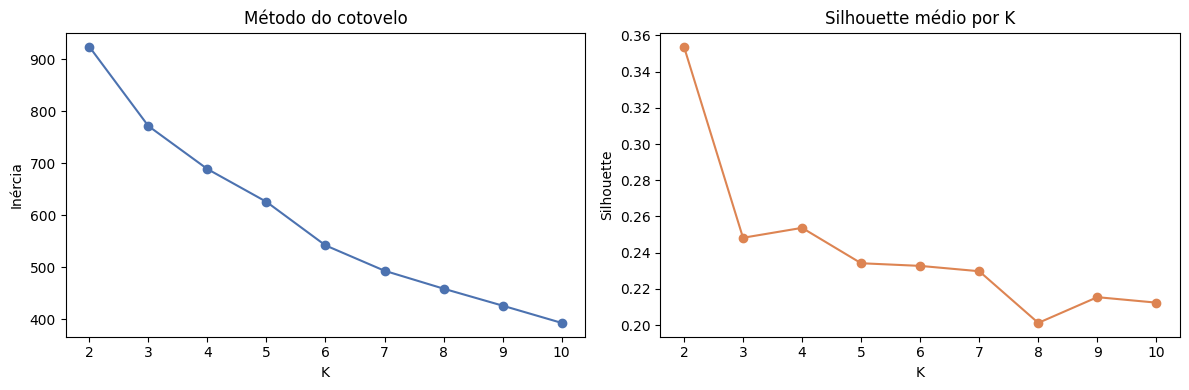

,Inércia,Silhouette
K,,
2,924.647,0.354
3,771.853,0.248
4,688.924,0.254
5,625.726,0.234
6,541.856,0.233
7,492.974,0.230
8,458.447,0.201
9,425.740,0.215
10,392.508,0.212


In [12]:
valores_k = range(2, 11)
inercias, silhuetas = [], []

for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    rotulos = km.fit_predict(X_scaled)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_scaled, rotulos))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(valores_k), inercias, "o-", color="#4C72B0")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inércia")
axes[0].set_title("Método do cotovelo")
axes[1].plot(list(valores_k), silhuetas, "o-", color="#DD8452")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette")
axes[1].set_title("Silhouette médio por K")
plt.tight_layout()
plt.show()

pd.DataFrame({"K": list(valores_k), "Inércia": inercias, "Silhouette": silhuetas}).set_index("K").round(3)

**Como ler os gráficos:**
- No **cotovelo**, a inércia sempre cai quando K aumenta (mais grupos = pontos mais perto de algum centro). Procuramos o ponto em que a
  queda deixa de ser grande. Neste dataset a curva costuma "dobrar" por volta de **K = 3**.
- O **silhouette** normalmente é maior em K = 2, porque separar só "ricos" e "pobres" é a divisão mais óbvia. Porém, 2 grupos é pouco
  informativo para o problema, e K = 3 mantém um silhouette próximo ao máximo.

Escolhemos **K = 3**, que equilibra as duas métricas e é fácil de interpretar: países de **baixo**, **médio** e **alto** desenvolvimento.

In [13]:
K = 3

kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
rotulos_km = renumerar_por_pib(kmeans.fit_predict(X_scaled))

NOMES = {0: "Baixo desenvolvimento", 1: "Desenvolvimento intermediário", 2: "Alto desenvolvimento"} if K == 3 else None

df["cluster_kmeans"] = rotulos_km
print("Países por grupo:")
print(df["cluster_kmeans"].map(NOMES or (lambda g: f"Grupo {g}")).value_counts())
print()
for nome, valor in metricas(rotulos_km).items():
    print(f"{nome}: {valor:.3f}" if isinstance(valor, float) else f"{nome}: {valor}")

Países por grupo:
cluster_kmeans
Desenvolvimento intermediário    65
Alto desenvolvimento             59
Baixo desenvolvimento            43
Name: count, dtype: int64

Nº de grupos: 3
Silhouette (↑): 0.248
Davies-Bouldin (↓): 1.368
Calinski-Harabasz (↑): 77.676


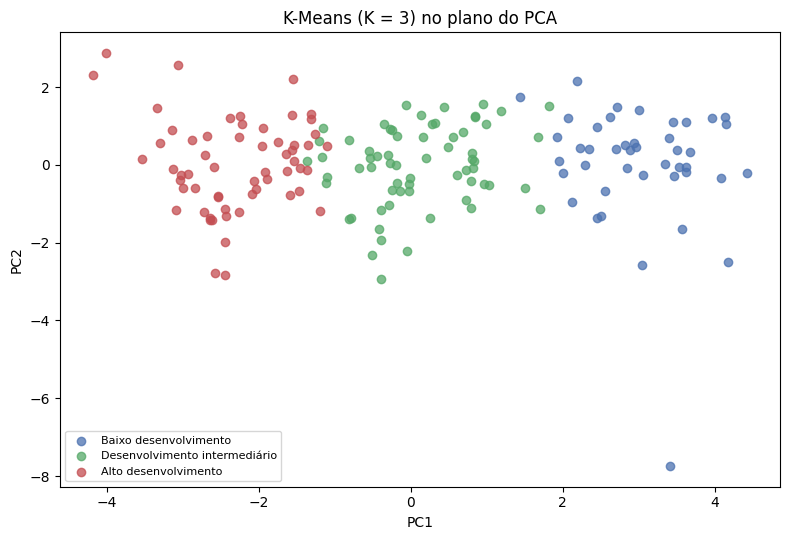

In [14]:
plot_clusters(rotulos_km, "K-Means (K = 3) no plano do PCA", NOMES)

### 5.2 Interpretando os grupos

O clustering só é útil se conseguirmos explicar **o que caracteriza** cada grupo. Para isso olhamos a média de cada variável
nos **valores originais** (sem log e sem padronização).

In [15]:
perfil = df.groupby("cluster_kmeans")[features].mean().round(1)
if NOMES:
    perfil.index = perfil.index.map(NOMES)
perfil

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
cluster_kmeans,,,,,,,,,
Baixo desenvolvimento,94.1,23.7,6.4,42.1,2096.8,11.6,59.6,5.0,951.4
Desenvolvimento intermediário,29.8,39.3,5.8,44.0,11276.6,10.0,70.6,2.6,5354.1
Alto desenvolvimento,6.9,55.8,8.3,53.6,34576.6,2.5,78.5,1.8,30103.2


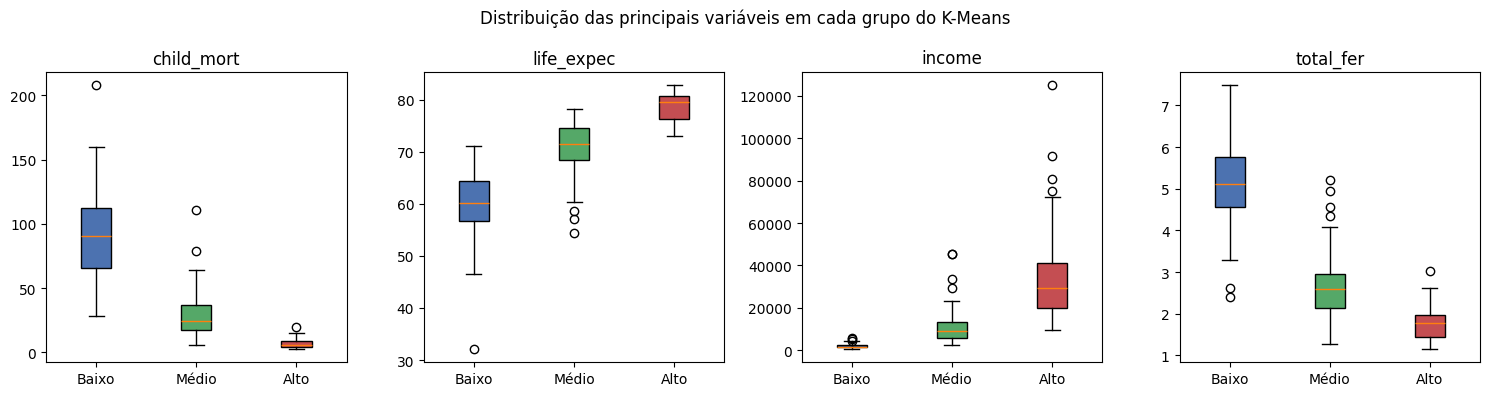

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["child_mort", "life_expec", "income", "total_fer"]):
    dados = [df.loc[df["cluster_kmeans"] == g, col] for g in range(K)]
    caixa = ax.boxplot(dados, patch_artist=True)
    for patch, cor in zip(caixa["boxes"], CORES):
        patch.set_facecolor(cor)
    ax.set_xticks(range(1, K + 1), ["Baixo", "Médio", "Alto"] if K == 3 else [str(g) for g in range(K)])
    ax.set_title(col)
plt.suptitle("Distribuição das principais variáveis em cada grupo do K-Means")
plt.tight_layout()
plt.show()

In [17]:
for g in range(K):
    paises = df.loc[df["cluster_kmeans"] == g, "country"].sort_values().tolist()
    titulo = NOMES[g] if NOMES else f"Grupo {g}"
    print(f"{titulo} ({len(paises)} países):")
    print(", ".join(paises))
    print()

Baixo desenvolvimento (43 países):
Afghanistan, Angola, Benin, Burkina Faso, Burundi, Cameroon, Central African Republic, Chad, Comoros, Congo, Dem. Rep., Cote d'Ivoire, Eritrea, Gambia, Ghana, Guinea, Guinea-Bissau, Haiti, Kenya, Kiribati, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Mozambique, Myanmar, Nepal, Niger, Nigeria, Pakistan, Rwanda, Senegal, Sierra Leone, Solomon Islands, Sudan, Tajikistan, Tanzania, Timor-Leste, Togo, Uganda, Yemen, Zambia

Desenvolvimento intermediário (65 países):
Albania, Algeria, Argentina, Armenia, Azerbaijan, Bangladesh, Belarus, Belize, Bhutan, Bolivia, Botswana, Brazil, Cambodia, Cape Verde, China, Colombia, Congo, Rep., Dominican Republic, Ecuador, Egypt, El Salvador, Equatorial Guinea, Fiji, Gabon, Georgia, Grenada, Guatemala, Guyana, India, Indonesia, Iran, Iraq, Jamaica, Jordan, Kazakhstan, Kyrgyz Republic, Lao, Libya, Micronesia, Fed. Sts., Moldova, Mongolia, Morocco, Namibia, Oman, Paraguay, Peru, Philippines, Romania, Russia, Sam

### 5.3 Aplicação: quais países mais precisam de ajuda?

Dentro do grupo de baixo desenvolvimento, ordenamos os países pela mortalidade infantil e pela renda.
Essa é uma forma simples de transformar o resultado do clustering em uma **recomendação prática**.

In [18]:
prioridade = (df[df["cluster_kmeans"] == 0]
              .sort_values(["child_mort", "income"], ascending=[False, True])
              [["country", "child_mort", "life_expec", "income", "gdpp"]]
              .head(10)
              .reset_index(drop=True))
prioridade.index += 1
prioridade

,country,child_mort,life_expec,income,gdpp
1,Haiti,208.0,32.1,1500,662
2,Sierra Leone,160.0,55.0,1220,399
3,Chad,150.0,56.5,1930,897
4,Central African Republic,149.0,47.5,888,446
5,Mali,137.0,59.5,1870,708
6,Nigeria,130.0,60.5,5150,2330
7,Niger,123.0,58.8,814,348
8,Angola,119.0,60.1,5900,3530
9,"Congo, Dem. Rep.",116.0,57.5,609,334
10,Burkina Faso,116.0,57.9,1430,575


## Referências

- Scikit-Learn – Clustering: https://scikit-learn.org/stable/modules/clustering.html
- KMeans: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- Scikit-Learn – Clustering performance evaluation: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
- Kaggle – Unsupervised Learning on Country Data: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data